# Previsão de Vendas com Regressão Linear

Treinamos um modelo de regressão linear (scikit-learn) sobre as vendas mensais de uma loja para entender a tendência e prever os próximos meses.

## 1. Importando bibliotecas e criando o DataFrame

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

In [2]:
dados_vendas = {
    'mes': ['Janeiro', 'Fevereiro', 'Março', 'Abril', 'Maio', 'Junho',
            'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro'],
    'vendas': [2000, 2200, 2300, 2500, 2600, 2700,
               2800, 2900, 3000, 3100, 3200, 3300]
}

df = pd.DataFrame(dados_vendas)
df['mes_num'] = range(1, len(df) + 1)
df

,mes,vendas,mes_num
0,Janeiro,2000,1
1,Fevereiro,2200,2
2,Março,2300,3
3,Abril,2500,4
4,Maio,2600,5
5,Junho,2700,6
6,Julho,2800,7
7,Agosto,2900,8
8,Setembro,3000,9
9,Outubro,3100,10


## 2. Preparando os dados (X e y)

In [3]:
X = df[['mes_num']]
y = df['vendas']

## 3. Treinando o modelo de regressão linear

In [4]:
modelo = LinearRegression()
modelo.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[113.29]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['mes_num']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1980
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


## 4. Coeficientes e qualidade do ajuste (R²)

In [5]:
print("Intercepto:", round(modelo.intercept_, 2))
print("Coeficiente (crescimento por mês):", round(modelo.coef_[0], 2))
print("R²:", round(modelo.score(X, y), 4))

Intercepto: 1980.3
Coeficiente (crescimento por mês): 113.29
R²: 0.9885


## 5. Prevendo vendas futuras

In [6]:
meses_futuros = pd.DataFrame({'mes_num': [13, 14, 15]})
previsoes = modelo.predict(meses_futuros)

for mes, venda in zip(meses_futuros['mes_num'], previsoes):
    print(f"Mês {mes}: R$ {venda:,.2f}")

Mês 13: R$ 3,453.03
Mês 14: R$ 3,566.32
Mês 15: R$ 3,679.60


## 6. Visualização

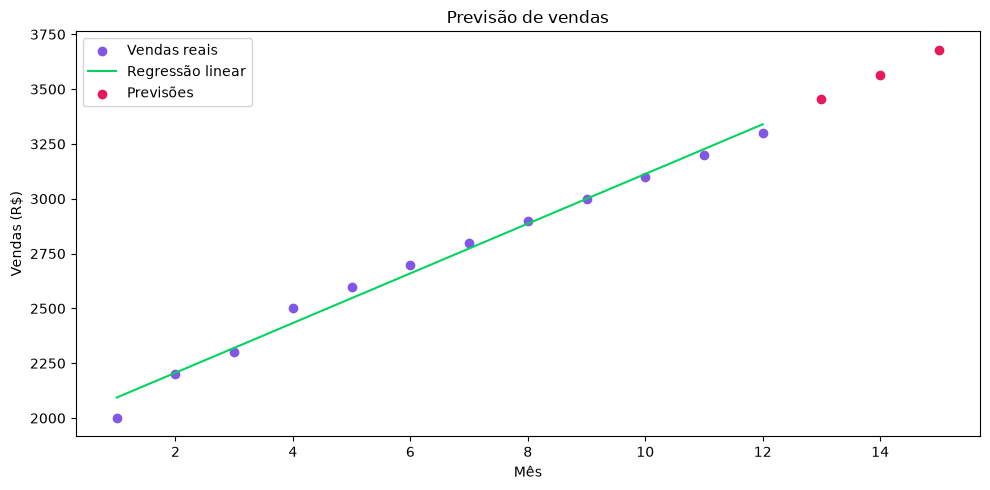

In [7]:
plt.figure(figsize=(10, 5))
plt.scatter(df['mes_num'], df['vendas'], color='#8257E6', label='Vendas reais')
plt.plot(df['mes_num'], modelo.predict(X), color='#04D361', label='Regressão linear')
plt.scatter(meses_futuros['mes_num'], previsoes, color='#E7195A', label='Previsões')
plt.title('Previsão de vendas')
plt.xlabel('Mês')
plt.ylabel('Vendas (R$)')
plt.legend()
plt.tight_layout()
plt.show()

## Conclusões

- Crescimento de cerca de R$ 113 por mês, partindo de um intercepto de aproximadamente R$ 1.980.
- R² de 0,99: a reta explica quase toda a variação das vendas.
- Previsões para os próximos três meses: aproximadamente R$ 3.453, R$ 3.566 e R$ 3.680.